<a href="https://colab.research.google.com/github/rumali-DS/S-P-500-Stock-Segmentation-RFM/blob/main/task2_%26_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 2 & Task 3 Graphs



## Cell 1 — Setup and load Task 1 feature table


In [ ]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import sklearn
from sklearn.preprocessing import StandardScaler
from IPython.display import display

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__, "| NumPy:", np.__version__)
print("scikit-learn:", sklearn.__version__, "| Matplotlib:", matplotlib.__version__)

FILE = "feature_table_common.csv"
DATA_PATH = Path("data") / FILE

if not DATA_PATH.is_file():
    DATA_PATH = Path(FILE)

# Check if a duplicated upload version exists (e.g., "feature_table_common (1).csv")
if not DATA_PATH.is_file():
    uploaded_alternatives = list(Path(".").glob("feature_table_common*.csv"))
    if uploaded_alternatives:
        # Sort to find the latest version, or just pick the first one
        DATA_PATH = sorted(uploaded_alternatives)[-1]
        print(f"Using automatically detected upload file: {DATA_PATH}")

if not DATA_PATH.is_file():
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(f"Place {FILE} in the current folder or data/.")
    print(f"Upload {FILE} exported from Task 1.")
    files.upload()

    # Re-evaluate after upload
    DATA_PATH = Path(FILE)
    if not DATA_PATH.is_file():
        uploaded_alternatives = list(Path(".").glob("feature_table_common*.csv"))
        if uploaded_alternatives:
            DATA_PATH = sorted(uploaded_alternatives)[-1]

if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Expected {FILE}; check the upload filename.")

raw_features = pd.read_csv(DATA_PATH, dtype={"ticker": str})
print("Loaded:", DATA_PATH)
print("Rows:", len(raw_features))
print("Columns:", raw_features.columns.tolist())

Python: 3.13.18
pandas: 2.2.3 | NumPy: 2.4.6
scikit-learn: 1.6.1 | Matplotlib: 3.10.0
Using automatically detected upload file: feature_table_common (1).csv
Loaded: feature_table_common (1).csv
Rows: 486
Columns: ['ticker', 'mean_weekly_return', 'weekly_beta', 'n_weekly_obs', 'last_event_date', 'R', 'F', 'M', 'name', 'sector', 'rfm_missing', 'nonfinite_features']


## Cell 2 — Validate the common share set


In [ ]:
FEATURES = ["mean_weekly_return", "weekly_beta", "R", "F", "M"]
EXPECTED_SHARES = 486
required = ["ticker"] + FEATURES
missing_columns = [c for c in required if c not in raw_features.columns]
if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}. Check the Task 1 CSV.")

if raw_features["ticker"].isna().any() or raw_features["ticker"].str.strip().eq("").any():
    raise ValueError("Missing or empty tickers.")
original = raw_features.copy(deep=True).set_index("ticker", verify_integrity=True)
if len(original) != EXPECTED_SHARES:
    raise ValueError(f"Expected {EXPECTED_SHARES} shares, found {len(original)}. Verify against Task 1 before proceeding.")

numeric = original[FEATURES].apply(pd.to_numeric, errors="raise")
if not np.isfinite(numeric.to_numpy(dtype=float)).all():
    raise ValueError("Missing or infinite numeric features; reconcile with Task 1.")
if not (numeric["R"].ge(0) & numeric["F"].between(0, 60) & numeric["M"].ge(0)).all():
    raise ValueError("Invalid R, F or M values.")
if not ((numeric[["R", "F"]] % 1) == 0).all().all():
    raise ValueError("R and F should be whole-day counts.")
if (numeric.nunique() < 2).any():
    raise ValueError("At least one feature is constant; investigate before clustering.")
print("Unique tickers:", original.index.is_unique)
print("Common share count:", len(numeric))
print("Missing and nonfinite feature values: 0")
print("RFM domain checks: passed")
display(numeric.describe().T)


Unique tickers: True
Common share count: 486
Missing and nonfinite feature values: 0
RFM domain checks: passed


,count,mean,std,min,25%,50%,75%,max
mean_weekly_return,486.0,2.857173e-03,2.651609e-03,-4.468094e-03,1.181530e-03,2.618931e-03,4.207324e-03,1.777248e-02
weekly_beta,486.0,9.736952e-01,4.073389e-01,5.545339e-02,6.665992e-01,9.506103e-01,1.179538e+00,3.778560e+00
R,486.0,2.040741e+01,2.134244e+01,4.000000e+00,1.100000e+01,1.100000e+01,1.475000e+01,2.220000e+02
F,486.0,2.989712e+00,1.330800e+00,0.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,8.000000e+00
M,486.0,3.940420e+10,1.291390e+11,1.297483e+09,1.019517e+10,1.668382e+10,3.227689e+10,1.847700e+12


## Cell 3 — Skewness and potential outliers


,skewness,lower_IQR_fence,upper_IQR_fence,IQR_flagged_count,IQR_flagged_percent
mean_weekly_return,0.8675,-3.400000e-03,8.700000e-03,15,3.0864
weekly_beta,1.1036,-1.028000e-01,1.948900e+00,10,2.0576
R,3.6458,5.375000e+00,2.037500e+01,115,23.6626
F,0.4247,-1.000000e+00,7.000000e+00,2,0.4115
M,11.6838,-2.292741e+10,6.539947e+10,45,9.2593


Shares flagged on at least one feature: 158


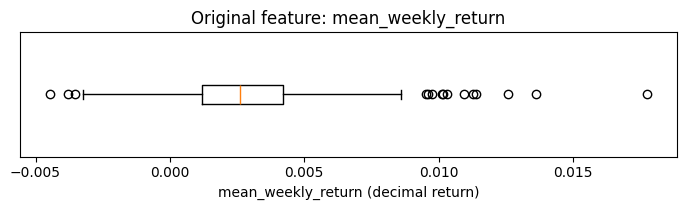

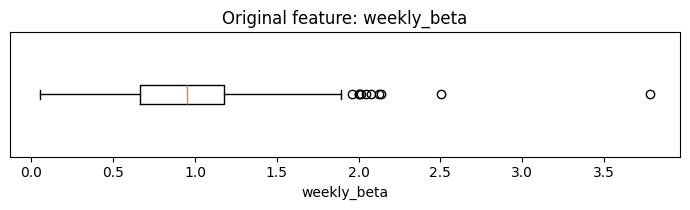

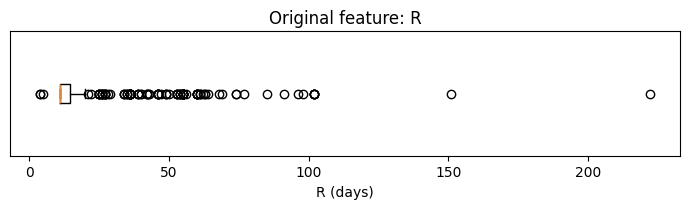

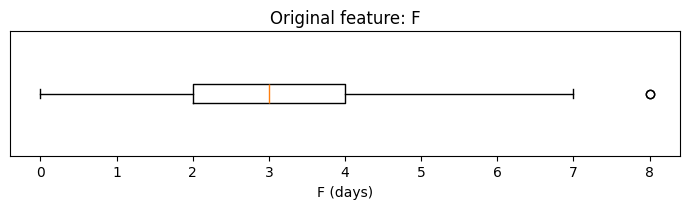

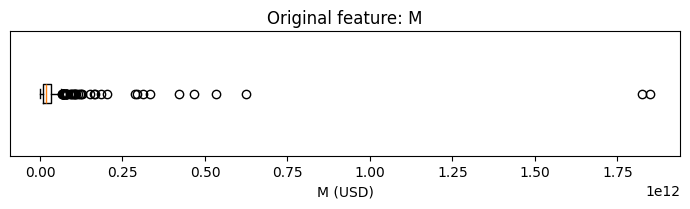

Largest Monetary observations (for review, not removal):


,mean_weekly_return,weekly_beta,R,F,M
ticker,,,,,
TSLA,0.005275,2.045761,50,5,1.847700e+12
NVDA,0.013624,2.125953,222,0,1.825340e+12
AAPL,0.003930,1.174835,11,2,6.233030e+11
MSFT,0.003982,1.128577,11,2,5.348980e+11
AMZN,0.002681,1.386667,11,5,4.681770e+11


In [ ]:
q1 = numeric.quantile(0.25)
q3 = numeric.quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
outlier_flags = numeric.lt(lower) | numeric.gt(upper)
diagnostics = pd.DataFrame({
    "skewness": numeric.skew(),
    "lower_IQR_fence": lower,
    "upper_IQR_fence": upper,
    "IQR_flagged_count": outlier_flags.sum(),
    "IQR_flagged_percent": 100 * outlier_flags.mean()
})
display(diagnostics.round(4))
print("Shares flagged on at least one feature:", int(outlier_flags.any(axis=1).sum()))

for col in FEATURES:
    fig, ax = plt.subplots(figsize=(7, 2.2))
    ax.boxplot(numeric[col].to_numpy(), vert=False)
    ax.set_title(f"Original feature: {col}")
    ax.set_xlabel(col + (" (USD)" if col == "M" else " (decimal return)" if col == "mean_weekly_return" else " (days)" if col in ["R", "F"] else ""))
    ax.set_yticks([])
    fig.tight_layout()
    plt.show()
    plt.close(fig)

print("Largest Monetary observations (for review, not removal):")
display(numeric.nlargest(5, "M"))

## Cell 4 — Explore logarithmic transformations


M: original skewness = 11.683807; log1p skewness = 1.079058


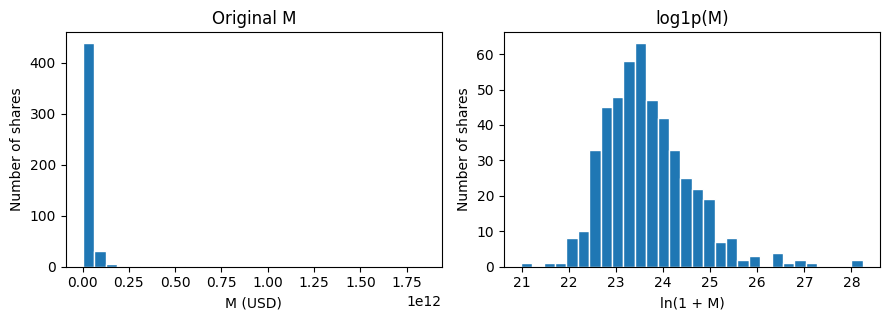

R: original skewness = 3.645784; log1p skewness = 1.583201


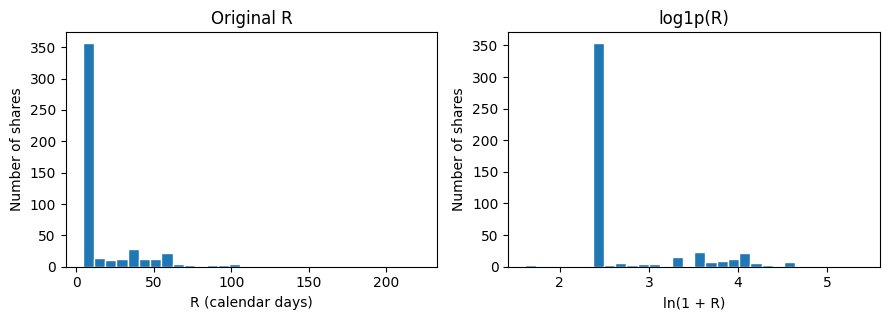

In [ ]:
for col in ["M", "R"]:
    before = numeric[col]
    after = np.log1p(before)
    print(f"{col}: original skewness = {before.skew():.6f}; log1p skewness = {after.skew():.6f}")
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.3))
    axes[0].hist(before, bins=30, edgecolor="white")
    axes[0].set_title(f"Original {col}")
    axes[0].set_xlabel(f"{col} ({'USD' if col == 'M' else 'calendar days'})")
    axes[1].hist(after, bins=30, edgecolor="white")
    axes[1].set_title(f"log1p({col})")
    axes[1].set_xlabel(f"ln(1 + {col})")
    for ax in axes:
        ax.set_ylabel("Number of shares")
    fig.tight_layout()
    plt.show()
    plt.close(fig)


# Cell 5 - Create two seperate feature metrics

In [ ]:
# Matrix 1: Risk and Return
risk_return = numeric[
    ["mean_weekly_return", "weekly_beta"]
].copy()

# Matrix 2: Trading Activity (RFM)
trading_activity = numeric[
    ["R", "F", "M"]
].copy()

# Apply logarithmic transformations
trading_activity["M"] = np.log1p(trading_activity["M"])
trading_activity["R"] = np.log1p(trading_activity["R"])

# Verify that both matrices contain the same shares
assert risk_return.index.equals(trading_activity.index)

print("Risk and Return matrix shape:", risk_return.shape)
print("Trading Activity matrix shape:", trading_activity.shape)

print("\nRisk and Return Matrix:")
display(risk_return.head())

print("\nTrading Activity Matrix (R and M log-transformed):")
display(trading_activity.head())

print("\nSkewness after selected transformations:")
display(pd.concat([
    risk_return.skew(),
    trading_activity.skew()
]).round(6))

Risk and Return matrix shape: (486, 2)
Trading Activity matrix shape: (486, 3)

Risk and Return Matrix:


,mean_weekly_return,weekly_beta
ticker,,
MMM,0.001142,0.869078
AOS,0.001991,1.042804
ABT,0.000971,0.583543
ABBV,0.003749,0.425365
ACN,0.002376,1.143300



Trading Activity Matrix (R and M log-transformed):


,R,F,M
ticker,,,
MMM,2.484907,4,23.981034
AOS,2.484907,2,22.281196
ABT,2.484907,1,24.285172
ABBV,2.484907,3,24.948208
ACN,2.484907,2,24.674400



Skewness after selected transformations:


,0
mean_weekly_return,0.867516
weekly_beta,1.103649
R,1.583201
F,0.424735
M,1.079058


# Cell 6 - Feature Standardisation

In [ ]:
# Create separate scalers for both matrices
scaler_risk = StandardScaler()
scaler_rfm = StandardScaler()

# Standardise Risk and Return features
X_risk = pd.DataFrame(
    scaler_risk.fit_transform(risk_return),
    index=risk_return.index,
    columns=risk_return.columns
)

# Standardise Trading Activity features
X_rfm = pd.DataFrame(
    scaler_rfm.fit_transform(trading_activity),
    index=trading_activity.index,
    columns=trading_activity.columns
)

print("Standardised Risk and Return Matrix:")
display(X_risk.head().round(4))

print("\nStandardised Trading Activity Matrix:")
display(X_rfm.head().round(4))

# Summarise standardised features
print("\nStandardised Feature Summary:")

scaled_summary = pd.concat([
    pd.DataFrame({
        "Mean": X_risk.mean(),
        "Standard Deviation": X_risk.std(ddof=0)
    }),
    pd.DataFrame({
        "Mean": X_rfm.mean(),
        "Standard Deviation": X_rfm.std(ddof=0)
    })
])

display(scaled_summary.round(6))

Standardised Risk and Return Matrix:


,mean_weekly_return,weekly_beta
ticker,,
MMM,-0.6473,-0.2571
AOS,-0.3271,0.1698
ABT,-0.7119,-0.9588
ABBV,0.3367,-1.3475
ACN,-0.1815,0.4168



Standardised Trading Activity Matrix:


,R,F,M
ticker,,,
MMM,-0.5259,0.7599,0.3176
AOS,-0.5259,-0.7445,-1.4884
ABT,-0.5259,-1.4967,0.6407
ABBV,-0.5259,0.0077,1.3451
ACN,-0.5259,-0.7445,1.0542



Standardised Feature Summary:


,Mean,Standard Deviation
mean_weekly_return,-0.0,1.0
weekly_beta,0.0,1.0
R,0.0,1.0
F,-0.0,1.0
M,-0.0,1.0


# Cell 7 - Final validation and export

In [ ]:
# Verify matrix dimensions
assert X_risk.shape == (EXPECTED_SHARES, 2)
assert X_rfm.shape == (EXPECTED_SHARES, 3)

# Verify identical tickers and row order
assert X_risk.index.equals(X_rfm.index)
assert X_risk.index.equals(numeric.index)

# Check for missing or infinite values
assert np.isfinite(X_risk.to_numpy()).all()
assert np.isfinite(X_rfm.to_numpy()).all()

# Verify logarithmic transformations
assert np.allclose(
    trading_activity["M"], np.log1p(numeric["M"])
)

assert np.allclose(
    trading_activity["R"], np.log1p(numeric["R"])
)

# Verify standardisation
for matrix in [X_risk, X_rfm]:
    assert np.allclose(matrix.mean(), 0, atol=1e-8)
    assert np.allclose(matrix.std(ddof=0), 1, atol=1e-8)

# Create output directory
out = Path("task2_outputs")
out.mkdir(exist_ok=True)

# Save prepared datasets
X_risk.to_csv(
    out / "risk_return_scaled.csv",
    index_label="ticker"
)

X_rfm.to_csv(
    out / "rfm_scaled.csv",
    index_label="ticker"
)

# Preserve original feature values and metadata
original.to_csv(
    out / "original_features.csv",
    index_label="ticker"
)

# Save feature diagnostics
diagnostics.to_csv(
    out / "feature_diagnostics.csv",
    index_label="feature"
)

# Save transformation and scaling parameters
scaling_parameters = pd.DataFrame({
    "Feature": FEATURES,
    "Transformation": [
        "None", "None", "log1p", "None", "log1p"
    ],
    "Scaler Mean": np.concatenate([
        scaler_risk.mean_, scaler_rfm.mean_
    ]),
    "Scaler Scale": np.concatenate([
        scaler_risk.scale_, scaler_rfm.scale_
    ])
})

scaling_parameters.to_csv(
    out / "scaling_parameters.csv",
    index=False
)

print("FINAL VALIDATION RESULTS")
print("------------------------")
print("Risk and Return matrix:", X_risk.shape)
print("Trading Activity matrix:", X_rfm.shape)
print("Common shares:", len(X_risk))
print("Identical ticker alignment: Passed")
print("Missing or infinite values: None")
print("Logarithmic transformation checks: Passed")
print("Standardisation checks: Passed")
print("Shares removed during feature preparation: 0")
print("\nAll validation checks passed successfully.")
print("Files saved to:", out.resolve())

FINAL VALIDATION RESULTS
------------------------
Risk and Return matrix: (486, 2)
Trading Activity matrix: (486, 3)
Common shares: 486
Identical ticker alignment: Passed
Missing or infinite values: None
Logarithmic transformation checks: Passed
Standardisation checks: Passed
Shares removed during feature preparation: 0

All validation checks passed successfully.
Files saved to: /content/task2_outputs


# Cell 8 - Import libraries and prepare Ward Linkage

In [ ]:
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from sklearn.metrics import silhouette_score

# Verify the input matrices
assert X_risk.shape == (486, 2)
assert X_rfm.shape == (486, 3)
assert X_risk.index.equals(X_rfm.index)

# Ward linkage with Euclidean distance
Z_risk = linkage(
    X_risk.to_numpy(),
    method="ward",
    metric="euclidean"
)

Z_rfm = linkage(
    X_rfm.to_numpy(),
    method="ward",
    metric="euclidean"
)

print("Risk and Return linkage shape:", Z_risk.shape)
print("Trading Activity linkage shape:", Z_rfm.shape)
print("Linkage method: Ward")
print("Distance metric: Euclidean")

Risk and Return linkage shape: (485, 4)
Trading Activity linkage shape: (485, 4)
Linkage method: Ward
Distance metric: Euclidean


# Cell 9 - Risk and Return Dendrogram

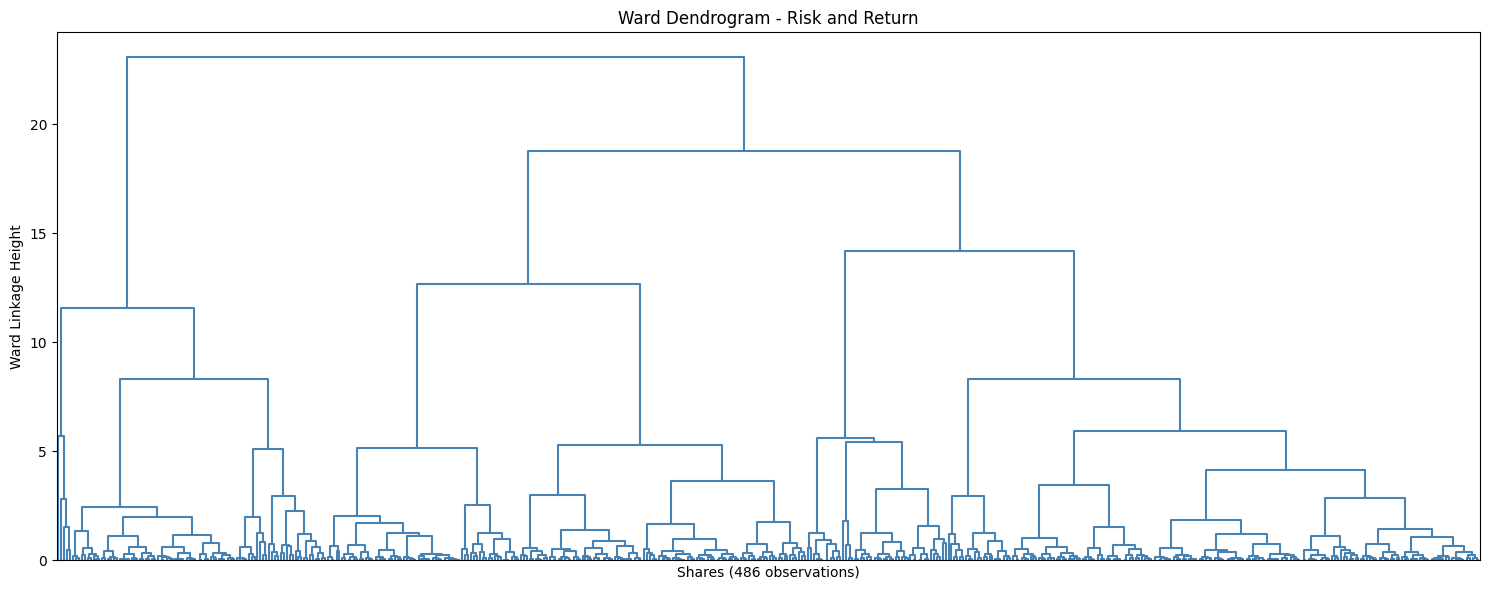

In [ ]:
plt.figure(figsize=(15, 6))

dendrogram(
    Z_risk,
    no_labels=True,
    color_threshold=0,
    above_threshold_color="steelblue"
)

plt.title("Ward Dendrogram - Risk and Return")
plt.xlabel("Shares (486 observations)")
plt.ylabel("Ward Linkage Height")
plt.tight_layout()

plt.savefig(
    out / "ward_risk_dendrogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Cell 10 - Trading activity Dedrogram

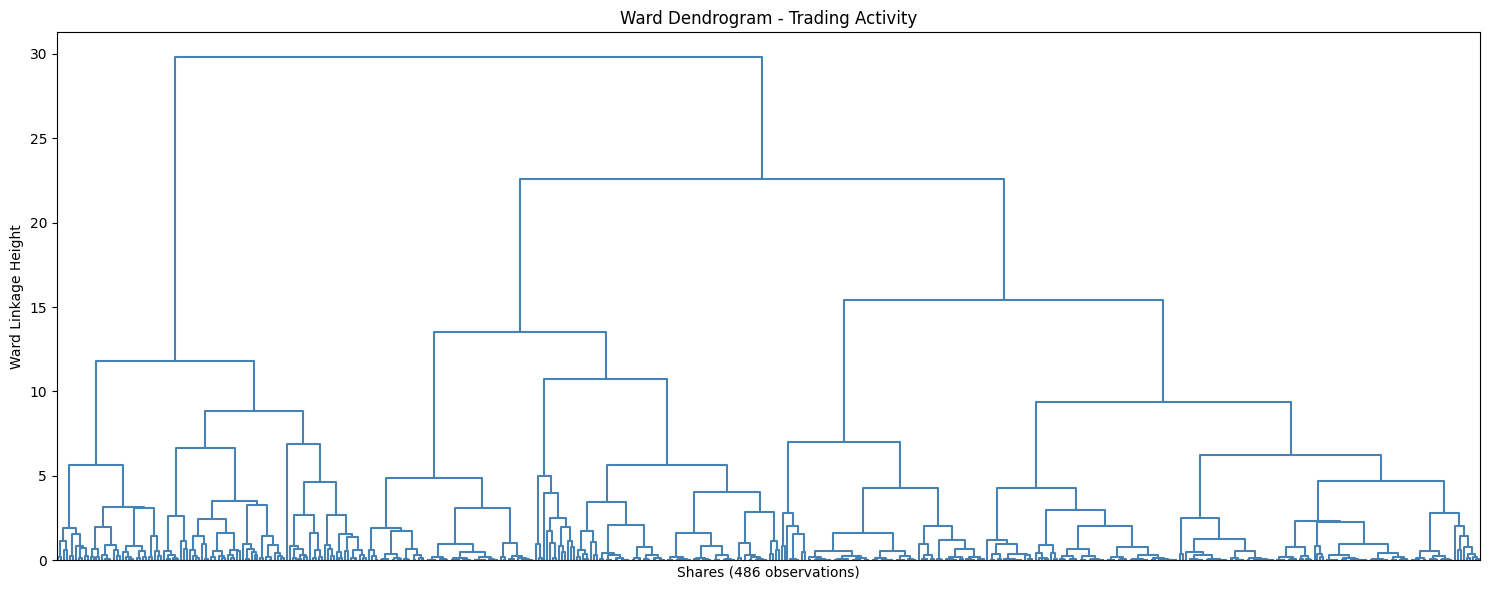

In [ ]:
plt.figure(figsize=(15, 6))

dendrogram(
    Z_rfm,
    no_labels=True,
    color_threshold=0,
    above_threshold_color="steelblue"
)

plt.title("Ward Dendrogram - Trading Activity")
plt.xlabel("Shares (486 observations)")
plt.ylabel("Ward Linkage Height")
plt.tight_layout()

plt.savefig(
    out / "ward_rfm_dendrogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Cell 11 - Evaluate cluster counts from k = 2 to 8

In [ ]:
def evaluate_ward(X, Z):

    results = []
    candidate_labels = {}

    n = len(X)

    for k in range(2, 9):

        # Obtain exactly k clusters from the Ward tree
        labels = cut_tree(
            Z, n_clusters=k
        ).ravel()

        assert len(np.unique(labels)) == k

        # Preserve ticker identities
        candidate_labels[k] = pd.Series(
            labels + 1,
            index=X.index,
            name="Cluster"
        )

        # Calculate silhouette score
        score = silhouette_score(
            X,
            labels,
            metric="euclidean"
        )

        # Calculate cluster sizes
        sizes = candidate_labels[k].value_counts().sort_index()

        # Gap between the merges surrounding this cut
        lower_height = Z[n - k - 1, 2]
        upper_height = Z[n - k, 2]
        merge_gap = upper_height - lower_height

        results.append({
            "k": k,
            "Silhouette Score": score,
            "Cluster Sizes": sizes.tolist(),
            "Smallest Cluster": sizes.min(),
            "Largest Cluster": sizes.max(),
            "Merge Height Gap": merge_gap
        })

    return pd.DataFrame(results), candidate_labels


# Evaluate Risk and Return
ward_risk_results, ward_risk_candidates = evaluate_ward(
    X_risk, Z_risk
)

# Evaluate Trading Activity
ward_rfm_results, ward_rfm_candidates = evaluate_ward(
    X_rfm, Z_rfm
)

print("Ward Clustering - Risk and Return")
display(ward_risk_results.round(4))

print("\nWard Clustering - Trading Activity")
display(ward_rfm_results.round(4))

# Save evaluation results
ward_risk_results.to_csv(
    out / "ward_risk_evaluation.csv",
    index=False
)

ward_rfm_results.to_csv(
    out / "ward_rfm_evaluation.csv",
    index=False
)

Ward Clustering - Risk and Return


,k,Silhouette Score,Cluster Sizes,Smallest Cluster,Largest Cluster,Merge Height Gap
0,2,0.3395,"[394, 92]",92,394,4.2706
1,3,0.2738,"[230, 164, 92]",92,230,4.5923
2,4,0.2821,"[182, 164, 48, 92]",48,182,1.5414
3,5,0.3041,"[182, 66, 98, 48, 92]",48,182,1.0677
4,6,0.3204,"[182, 66, 98, 48, 87, 5]",5,182,3.2599
5,7,0.3240,"[160, 66, 98, 48, 22, 87, 5]",5,160,0.0332
6,8,0.3208,"[160, 66, 98, 48, 22, 56, 31, 5]",5,160,2.3794



Ward Clustering - Trading Activity


,k,Silhouette Score,Cluster Sizes,Smallest Cluster,Largest Cluster,Merge Height Gap
0,2,0.4020,"[380, 106]",106,380,7.1831
1,3,0.3352,"[141, 239, 106]",106,239,7.1696
2,4,0.2925,"[141, 169, 106, 70]",70,169,1.8743
3,5,0.2860,"[84, 169, 57, 106, 70]",57,169,1.7624
4,6,0.2760,"[84, 169, 57, 36, 70, 70]",36,169,1.0175
5,7,0.2969,"[70, 169, 57, 14, 36, 70, 70]",14,169,1.4075
6,8,0.2990,"[70, 66, 57, 14, 36, 70, 70, 103]",14,103,0.5040


# Cell 12 - Visualise silhouette scores

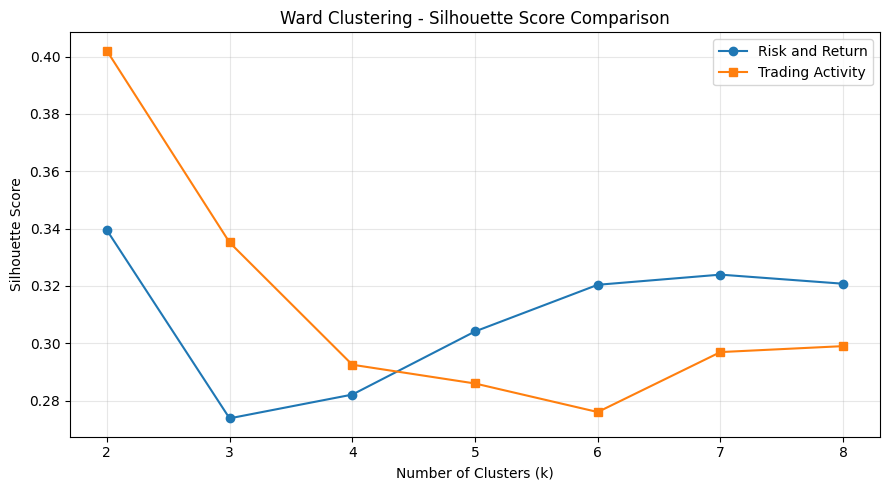

Highest silhouette score - Risk and Return:


,k,Silhouette Score,Cluster Sizes,Smallest Cluster,Largest Cluster,Merge Height Gap
0,2,0.339485,"[394, 92]",92,394,4.27063


Highest silhouette score - Trading Activity:


,k,Silhouette Score,Cluster Sizes,Smallest Cluster,Largest Cluster,Merge Height Gap
0,2,0.402044,"[380, 106]",106,380,7.183137


In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    ward_risk_results["k"],
    ward_risk_results["Silhouette Score"],
    marker="o",
    label="Risk and Return"
)

plt.plot(
    ward_rfm_results["k"],
    ward_rfm_results["Silhouette Score"],
    marker="s",
    label="Trading Activity"
)

plt.title("Ward Clustering - Silhouette Score Comparison")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 9))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    out / "ward_silhouette_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Highest silhouette score - Risk and Return:")
display(
    ward_risk_results.nlargest(1, "Silhouette Score")
)

print("Highest silhouette score - Trading Activity:")
display(
    ward_rfm_results.nlargest(1, "Silhouette Score")
)

# Cell 13 - Examine candidate cluster profiles

In [ ]:
# Risk and Return cluster profiles
risk_profiles = []

for k in range(2, 9):

    temp = numeric[
        ["mean_weekly_return", "weekly_beta"]
    ].copy()

    temp["Cluster"] = ward_risk_candidates[k]

    # Convert return to percentage for interpretation
    temp["mean_weekly_return"] *= 100

    profile = temp.groupby("Cluster").agg(
        Shares=("weekly_beta", "size"),
        Mean_Weekly_Return_Pct=("mean_weekly_return", "mean"),
        Mean_Beta=("weekly_beta", "mean")
    )

    profile.insert(0, "k", k)
    risk_profiles.append(profile.reset_index())

ward_risk_profiles = pd.concat(
    risk_profiles,
    ignore_index=True
)

print("Risk and Return - Candidate Cluster Profiles")
display(ward_risk_profiles.round(4))


# Trading Activity cluster profiles
rfm_profiles = []

for k in range(2, 9):

    temp = numeric[["R", "F", "M"]].copy()

    temp["Cluster"] = ward_rfm_candidates[k]

    # Convert Monetary to USD billions
    temp["M"] /= 1e9

    profile = temp.groupby("Cluster").agg(
        Shares=("R", "size"),
        Median_Recency=("R", "median"),
        Median_Frequency=("F", "median"),
        Median_Monetary_USD_Bn=("M", "median")
    )

    profile.insert(0, "k", k)
    rfm_profiles.append(profile.reset_index())

ward_rfm_profiles = pd.concat(
    rfm_profiles,
    ignore_index=True
)

print("Trading Activity - Candidate Cluster Profiles")
display(ward_rfm_profiles.round(4))


# Save candidate profiles
ward_risk_profiles.to_csv(
    out / "ward_risk_candidate_profiles.csv",
    index=False
)

ward_rfm_profiles.to_csv(
    out / "ward_rfm_candidate_profiles.csv",
    index=False
)

Risk and Return - Candidate Cluster Profiles


,Cluster,k,Shares,Mean_Weekly_Return_Pct,Mean_Beta
0,1,2,394,0.2048,0.8979
1,2,2,92,0.6321,1.2981
2,1,3,230,0.1459,1.1096
3,2,3,164,0.2875,0.6012
4,3,3,92,0.6321,1.2981
5,1,4,182,0.1317,0.9728
6,2,4,164,0.2875,0.6012
7,3,4,48,0.1999,1.6280
8,4,4,92,0.6321,1.2981
9,1,5,182,0.1317,0.9728


Trading Activity - Candidate Cluster Profiles


,Cluster,k,Shares,Median_Recency,Median_Frequency,Median_Monetary_USD_Bn
0,1,2,380,11.0,3.0,15.4731
1,2,2,106,46.5,2.0,19.4850
2,1,3,141,11.0,3.0,42.0131
3,2,3,239,11.0,3.0,11.1536
4,3,3,106,46.5,2.0,19.4850
5,1,4,141,11.0,3.0,42.0131
6,2,4,169,11.0,3.0,9.2664
7,3,4,106,46.5,2.0,19.4850
8,4,4,70,11.0,4.0,13.7642
9,1,5,84,11.0,4.0,49.2644


# Cell 14 - Save final ward clustering assignments

In [ ]:
# Selected cluster counts
K_RISK = 2
K_RFM = 3

# Retrieve final Ward cluster assignments
ward_risk_labels = ward_risk_candidates[K_RISK].rename(
    "ward_risk_cluster"
)

ward_rfm_labels = ward_rfm_candidates[K_RFM].rename(
    "ward_rfm_cluster"
)

# Combine assignments using the same share tickers
ward_assignments = pd.concat(
    [ward_risk_labels, ward_rfm_labels],
    axis=1
)

# Validate assignments
assert len(ward_assignments) == 486
assert ward_assignments.index.equals(X_risk.index)
assert ward_assignments.notna().all().all()
assert ward_risk_labels.nunique() == K_RISK
assert ward_rfm_labels.nunique() == K_RFM

# Save assignments for Tasks 2.4 and 3
ward_assignments.to_csv(
    out / "ward_final_assignments.csv",
    index_label="ticker"
)

print("Final Risk and Return clusters:", K_RISK)
print("Final Trading Activity clusters:", K_RFM)

print("\nRisk and Return cluster sizes:")
print(ward_risk_labels.value_counts().sort_index())

print("\nTrading Activity cluster sizes:")
print(ward_rfm_labels.value_counts().sort_index())

print("\nFinal Ward Silhouette Scores:")
print(
    "Risk and Return:",
    round(silhouette_score(X_risk, ward_risk_labels), 4)
)
print(
    "Trading Activity:",
    round(silhouette_score(X_rfm, ward_rfm_labels), 4)
)

print("\nFinal cluster assignments:")
display(ward_assignments.head(10))

print("\nFinal Risk and Return profiles:")
display(
    ward_risk_profiles[
        ward_risk_profiles["k"] == K_RISK
    ].round(4)
)

print("\nFinal Trading Activity profiles:")
display(
    ward_rfm_profiles[
        ward_rfm_profiles["k"] == K_RFM
    ].round(4)
)

print("\nFinal Ward assignments saved successfully.")

Final Risk and Return clusters: 2
Final Trading Activity clusters: 3

Risk and Return cluster sizes:
ward_risk_cluster
1    394
2     92
Name: count, dtype: int64

Trading Activity cluster sizes:
ward_rfm_cluster
1    141
2    239
3    106
Name: count, dtype: int64

Final Ward Silhouette Scores:
Risk and Return: 0.3395
Trading Activity: 0.3352

Final cluster assignments:


,ward_risk_cluster,ward_rfm_cluster
ticker,,
MMM,1,1
AOS,1,2
ABT,1,1
ABBV,1,1
ACN,1,1
ADBE,1,1
AMD,1,1
AES,1,3
AFL,1,2



Final Risk and Return profiles:


,Cluster,k,Shares,Mean_Weekly_Return_Pct,Mean_Beta
0,1,2,394,0.2048,0.8979
1,2,2,92,0.6321,1.2981



Final Trading Activity profiles:


,Cluster,k,Shares,Median_Recency,Median_Frequency,Median_Monetary_USD_Bn
2,1,3,141,11.0,3.0,42.0131
3,2,3,239,11.0,3.0,11.1536
4,3,3,106,46.5,2.0,19.4850



Final Ward assignments saved successfully.


# Cell 15 - K-means model evaluation

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Verify the prepared feature matrices
assert X_risk.shape == (486, 2)
assert X_rfm.shape == (486, 3)
assert X_risk.index.equals(X_rfm.index)

def evaluate_kmeans(X):
    results = []
    candidates = {}

    for k in range(2, 9):

        model = KMeans(
            n_clusters=k,
            init="k-means++",
            n_init=30,
            random_state=42,
            max_iter=500
        )

        labels0 = model.fit_predict(X)

        assert len(np.unique(labels0)) == k

        labels = pd.Series(
            labels0 + 1,
            index=X.index,
            name="Cluster"
        )

        candidates[k] = labels
        sizes = labels.value_counts().sort_index()

        results.append({
            "k": k,
            "Silhouette Score": silhouette_score(
                X, labels0, metric="euclidean"
            ),
            "Inertia": model.inertia_,
            "Cluster Sizes": sizes.tolist(),
            "Smallest Cluster": int(sizes.min()),
            "Largest Cluster": int(sizes.max())
        })

    return pd.DataFrame(results), candidates


# Risk and Return
km_risk_results, km_risk_candidates = evaluate_kmeans(
    X_risk
)

# Trading Activity
km_rfm_results, km_rfm_candidates = evaluate_kmeans(
    X_rfm
)

print("K-means - Risk and Return:")
display(km_risk_results.round(4))

print("\nK-means - Trading Activity:")
display(km_rfm_results.round(4))

# Save evaluation evidence
km_risk_results.to_csv(
    out / "kmeans_risk_evaluation.csv",
    index=False
)

km_rfm_results.to_csv(
    out / "kmeans_rfm_evaluation.csv",
    index=False
)

print("\nK-means evaluation completed successfully.")

K-means - Risk and Return:


,k,Silhouette Score,Inertia,Cluster Sizes,Smallest Cluster,Largest Cluster
0,2,0.3870,621.6344,"[143, 343]",143,343
1,3,0.3289,461.1787,"[202, 165, 119]",119,202
2,4,0.3270,371.5770,"[132, 154, 40, 160]",40,160
3,5,0.3406,309.6130,"[112, 166, 131, 27, 50]",27,166
4,6,0.3349,265.0970,"[156, 127, 50, 105, 43, 5]",5,156
5,7,0.3315,227.4763,"[83, 74, 143, 85, 5, 48, 48]",5,143
6,8,0.3542,194.3617,"[136, 43, 76, 78, 5, 29, 40, 79]",5,136



K-means - Trading Activity:


,k,Silhouette Score,Inertia,Cluster Sizes,Smallest Cluster,Largest Cluster
0,2,0.4154,999.5204,"[384, 102]",102,384
1,3,0.3430,742.4933,"[257, 139, 90]",90,257
2,4,0.3617,559.2438,"[82, 194, 90, 120]",82,194
3,5,0.3482,480.7441,"[141, 87, 40, 99, 119]",40,141
4,6,0.3446,421.1942,"[139, 31, 38, 96, 113, 69]",31,139
5,7,0.3402,377.5821,"[147, 68, 30, 47, 94, 80, 20]",20,147
6,8,0.3457,343.6370,"[135, 29, 22, 19, 61, 86, 67, 67]",19,135



K-means evaluation completed successfully.


# Cell 16 - Silhouette score comparison

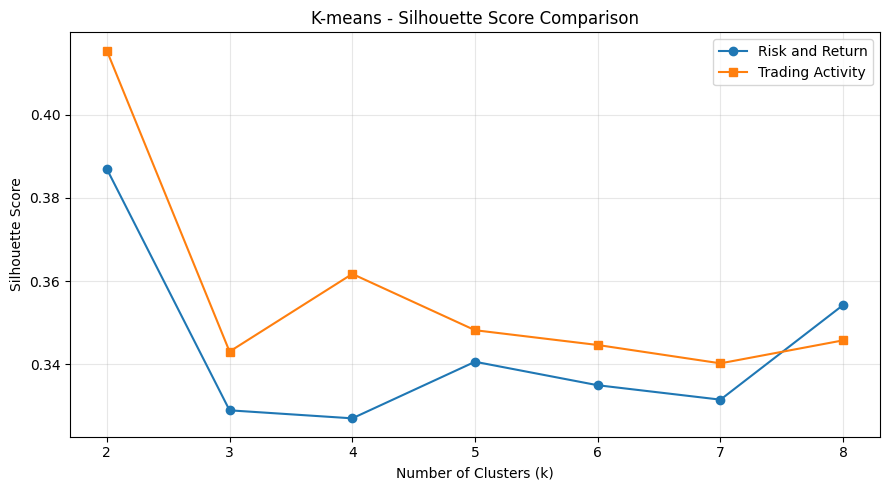

Highest silhouette score - Risk and Return:


,k,Silhouette Score,Inertia,Cluster Sizes,Smallest Cluster,Largest Cluster
0,2,0.38695,621.634358,"[143, 343]",143,343



Highest silhouette score - Trading Activity:


,k,Silhouette Score,Inertia,Cluster Sizes,Smallest Cluster,Largest Cluster
0,2,0.4154,999.520388,"[384, 102]",102,384


In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    km_risk_results["k"],
    km_risk_results["Silhouette Score"],
    marker="o",
    label="Risk and Return"
)

plt.plot(
    km_rfm_results["k"],
    km_rfm_results["Silhouette Score"],
    marker="s",
    label="Trading Activity"
)

plt.title("K-means - Silhouette Score Comparison")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 9))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    out / "kmeans_silhouette_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Highest silhouette score - Risk and Return:")
display(
    km_risk_results.nlargest(1, "Silhouette Score")
)

print("\nHighest silhouette score - Trading Activity:")
display(
    km_rfm_results.nlargest(1, "Silhouette Score")
)

# Cell 17 - Elbow method using inertia

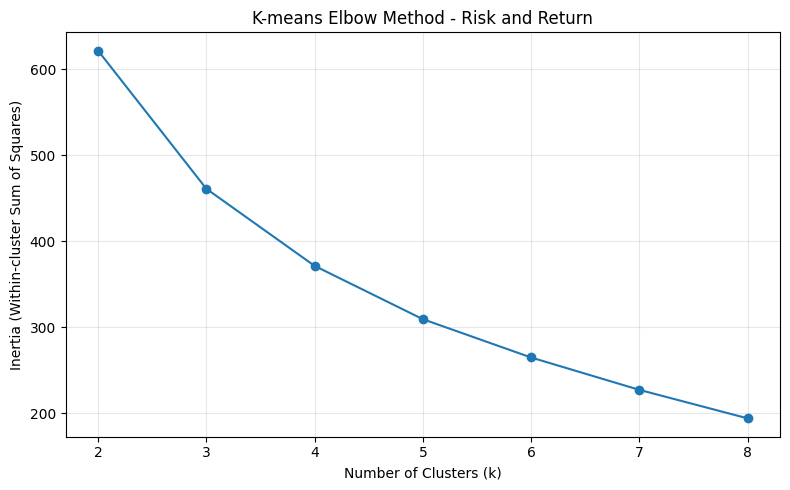

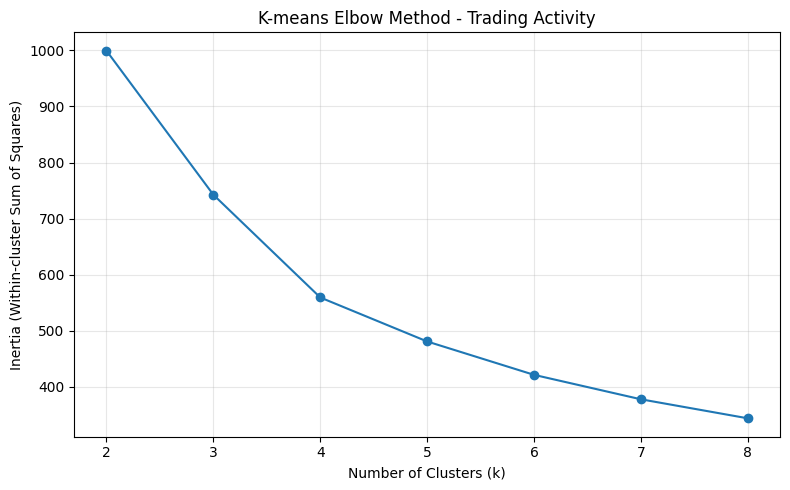

In [ ]:
for name, results, filename in [
    (
        "Risk and Return",
        km_risk_results,
        "kmeans_risk_elbow.png"
    ),
    (
        "Trading Activity",
        km_rfm_results,
        "kmeans_rfm_elbow.png"
    )
]:

    plt.figure(figsize=(8, 5))

    plt.plot(
        results["k"],
        results["Inertia"],
        marker="o"
    )

    plt.title(f"K-means Elbow Method - {name}")
    plt.xlabel("Number of Clusters (k)")
    plt.ylabel("Inertia (Within-cluster Sum of Squares)")
    plt.xticks(range(2, 9))
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        out / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

# Cell 18 - Candidate cluster profiles

In [ ]:
def make_kmeans_profiles(results, candidates, kind):

    top_k = int(
        results.loc[
            results["Silhouette Score"].idxmax(), "k"
        ]
    )

    ks_to_profile = sorted({2, 3, 4, top_k})
    sections = []

    for k in ks_to_profile:

        if kind == "risk":

            temp = numeric[
                ["mean_weekly_return", "weekly_beta"]
            ].copy()

            temp["Cluster"] = candidates[k]

            # Convert returns to percentages
            temp["mean_weekly_return"] *= 100

            profile = temp.groupby("Cluster").agg(
                Shares=("weekly_beta", "size"),
                Mean_Weekly_Return_Pct=(
                    "mean_weekly_return", "mean"
                ),
                Mean_Beta=("weekly_beta", "mean")
            )

        else:

            temp = numeric[["R", "F", "M"]].copy()
            temp["Cluster"] = candidates[k]

            # Convert original Monetary to USD billions
            temp["M"] /= 1e9

            profile = temp.groupby("Cluster").agg(
                Shares=("R", "size"),
                Median_Recency_Days=("R", "median"),
                Median_Frequency_Days=("F", "median"),
                Median_Monetary_USD_Bn=("M", "median")
            )

        profile.insert(0, "k", k)
        sections.append(profile.reset_index())

    return pd.concat(sections, ignore_index=True)


km_risk_profiles = make_kmeans_profiles(
    km_risk_results,
    km_risk_candidates,
    "risk"
)

km_rfm_profiles = make_kmeans_profiles(
    km_rfm_results,
    km_rfm_candidates,
    "rfm"
)

print("K-means - Risk and Return Candidate Profiles")
display(km_risk_profiles.round(4))

print("\nK-means - Trading Activity Candidate Profiles")
display(km_rfm_profiles.round(4))

# Save candidate profiles
km_risk_profiles.to_csv(
    out / "kmeans_risk_candidate_profiles.csv",
    index=False
)

km_rfm_profiles.to_csv(
    out / "kmeans_rfm_candidate_profiles.csv",
    index=False
)

K-means - Risk and Return Candidate Profiles


,Cluster,k,Shares,Mean_Weekly_Return_Pct,Mean_Beta
0,1,2,143,0.5330,1.3505
1,2,2,343,0.1826,0.8166
2,1,3,202,0.2593,0.6308
3,2,3,165,0.0946,1.1391
4,3,3,119,0.5955,1.3264
5,1,4,132,0.0842,1.2030
6,2,4,154,0.1690,0.5766
7,3,4,40,0.7253,1.7085
8,4,4,160,0.4544,0.9830



K-means - Trading Activity Candidate Profiles


,Cluster,k,Shares,Median_Recency_Days,Median_Frequency_Days,Median_Monetary_USD_Bn
0,1,2,384,11.0,3.0,15.2624
1,2,2,102,49.0,2.0,21.1834
2,1,3,257,11.0,3.0,11.2016
3,2,3,139,11.0,3.0,42.8916
4,3,3,90,53.5,2.0,21.1834
5,1,4,82,11.0,3.0,63.9579
6,2,4,194,11.0,2.0,13.1048
7,3,4,90,53.5,2.0,21.4501
8,4,4,120,11.0,4.0,12.7410


# Cell 19 - Save final K means cluster assignments

In [ ]:
# Final selected cluster counts
K_KM_RISK = 2
K_KM_RFM = 4

# Retrieve final K-means assignments
km_risk_labels = km_risk_candidates[K_KM_RISK].rename(
    "kmeans_risk_cluster"
)

km_rfm_labels = km_rfm_candidates[K_KM_RFM].rename(
    "kmeans_rfm_cluster"
)

# Combine assignments
km_assignments = pd.concat(
    [km_risk_labels, km_rfm_labels],
    axis=1
)

# Validate results
assert km_assignments.shape == (486, 2)
assert km_assignments.index.equals(X_risk.index)
assert km_assignments.notna().all().all()
assert km_risk_labels.nunique() == K_KM_RISK
assert km_rfm_labels.nunique() == K_KM_RFM

# Save assignments
km_assignments.to_csv(
    out / "kmeans_final_assignments.csv",
    index_label="ticker"
)

# Display final evaluation
print("FINAL K-MEANS RESULTS")

for name, X, labels in [
    ("Risk and Return", X_risk, km_risk_labels),
    ("Trading Activity", X_rfm, km_rfm_labels)
]:
    print(f"\n{name}")
    print("Clusters:", labels.nunique())
    print("Cluster sizes:")
    print(labels.value_counts().sort_index())
    print(
        "Silhouette score:",
        round(silhouette_score(X, labels), 4)
    )

print("\nFinal Risk and Return profiles:")
display(
    km_risk_profiles[
        km_risk_profiles["k"] == K_KM_RISK
    ].round(4)
)

print("\nFinal Trading Activity profiles:")
display(
    km_rfm_profiles[
        km_rfm_profiles["k"] == K_KM_RFM
    ].round(4)
)

print("\nFinal assignments saved successfully.")

FINAL K-MEANS RESULTS

Risk and Return
Clusters: 2
Cluster sizes:
kmeans_risk_cluster
1    143
2    343
Name: count, dtype: int64
Silhouette score: 0.387

Trading Activity
Clusters: 4
Cluster sizes:
kmeans_rfm_cluster
1     82
2    194
3     90
4    120
Name: count, dtype: int64
Silhouette score: 0.3617

Final Risk and Return profiles:


,Cluster,k,Shares,Mean_Weekly_Return_Pct,Mean_Beta
0,1,2,143,0.5330,1.3505
1,2,2,343,0.1826,0.8166



Final Trading Activity profiles:


,Cluster,k,Shares,Median_Recency_Days,Median_Frequency_Days,Median_Monetary_USD_Bn
5,1,4,82,11.0,3.0,63.9579
6,2,4,194,11.0,2.0,13.1048
7,3,4,90,53.5,2.0,21.4501
8,4,4,120,11.0,4.0,12.7410



Final assignments saved successfully.


# Cell - 20 Compare cluster profiles in original units

In [ ]:
# Cell 20: Original-unit cluster profiles

# Check that all cluster assignments are aligned
for labels in [
    ward_risk_labels,
    km_risk_labels,
    ward_rfm_labels,
    km_rfm_labels
]:
    assert labels.index.equals(numeric.index)
    assert labels.notna().all()

def risk_profile(labels, algorithm):

    data = numeric[
        ["mean_weekly_return", "weekly_beta"]
    ].copy()

    data["Cluster"] = labels

    # Convert returns from decimals into percentages
    data["Return_Pct"] = data["mean_weekly_return"] * 100

    profile = data.groupby("Cluster").agg(
        Shares=("weekly_beta", "size"),
        Mean_Weekly_Return_Pct=("Return_Pct", "mean"),
        Mean_Beta=("weekly_beta", "mean")
    ).reset_index()

    profile.insert(0, "Algorithm", algorithm)

    return profile


def rfm_profile(labels, algorithm):

    data = numeric[["R", "F", "M"]].copy()

    data["Cluster"] = labels
    data["M_USD_Bn"] = data["M"] / 1e9

    profile = data.groupby("Cluster").agg(
        Shares=("R", "size"),
        Median_Recency_Days=("R", "median"),
        Median_Frequency=("F", "median"),
        Median_Monetary_USD_Bn=("M_USD_Bn", "median")
    ).reset_index()

    profile.insert(0, "Algorithm", algorithm)

    return profile


# Combine Ward and K-means profiles
risk_comparison = pd.concat([
    risk_profile(ward_risk_labels, "Ward"),
    risk_profile(km_risk_labels, "K-means")
], ignore_index=True)

rfm_comparison = pd.concat([
    rfm_profile(ward_rfm_labels, "Ward"),
    rfm_profile(km_rfm_labels, "K-means")
], ignore_index=True)

print("Risk and Return - Algorithm Comparison")
display(risk_comparison.round(4))

print("\nTrading Activity - Algorithm Comparison")
display(rfm_comparison.round(4))

# Save profiles
risk_comparison.to_csv(
    out / "risk_algorithm_profiles.csv",
    index=False
)

rfm_comparison.to_csv(
    out / "rfm_algorithm_profiles.csv",
    index=False
)

Risk and Return - Algorithm Comparison


,Algorithm,Cluster,Shares,Mean_Weekly_Return_Pct,Mean_Beta
0,Ward,1,394,0.2048,0.8979
1,Ward,2,92,0.6321,1.2981
2,K-means,1,143,0.5330,1.3505
3,K-means,2,343,0.1826,0.8166



Trading Activity - Algorithm Comparison


,Algorithm,Cluster,Shares,Median_Recency_Days,Median_Frequency,Median_Monetary_USD_Bn
0,Ward,1,141,11.0,3.0,42.0131
1,Ward,2,239,11.0,3.0,11.1536
2,Ward,3,106,46.5,2.0,19.4850
3,K-means,1,82,11.0,3.0,63.9579
4,K-means,2,194,11.0,2.0,13.1048
5,K-means,3,90,53.5,2.0,21.4501
6,K-means,4,120,11.0,4.0,12.7410


# Cell 21 - Risk and Return 2D visualisation

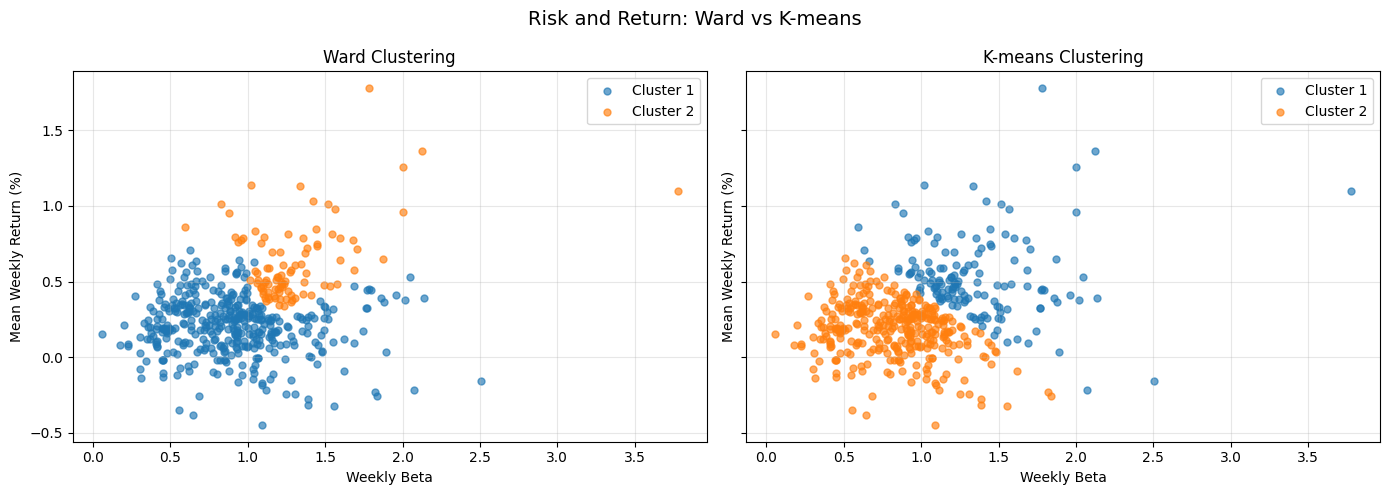

In [ ]:
# Cell 21: Risk and Return 2D visualisations

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    sharex=True,
    sharey=True
)

models = [
    ("Ward Clustering", ward_risk_labels),
    ("K-means Clustering", km_risk_labels)
]

for ax, (title, labels) in zip(axes, models):

    for cluster in sorted(labels.unique()):

        tickers = labels.index[labels == cluster]
        subset = numeric.loc[tickers]

        ax.scatter(
            subset["weekly_beta"],
            subset["mean_weekly_return"] * 100,
            label=f"Cluster {cluster}",
            s=25,
            alpha=0.65
        )

    ax.set_title(title)
    ax.set_xlabel("Weekly Beta")
    ax.set_ylabel("Mean Weekly Return (%)")
    ax.legend()
    ax.grid(alpha=0.3)

fig.suptitle(
    "Risk and Return: Ward vs K-means",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    out / "risk_ward_vs_kmeans.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Cell - 22 Trading Activity 2D visualisation using PCA

PCA Explained Variance:
PC1: 43.59%
PC2: 33.65%
Total: 77.24%


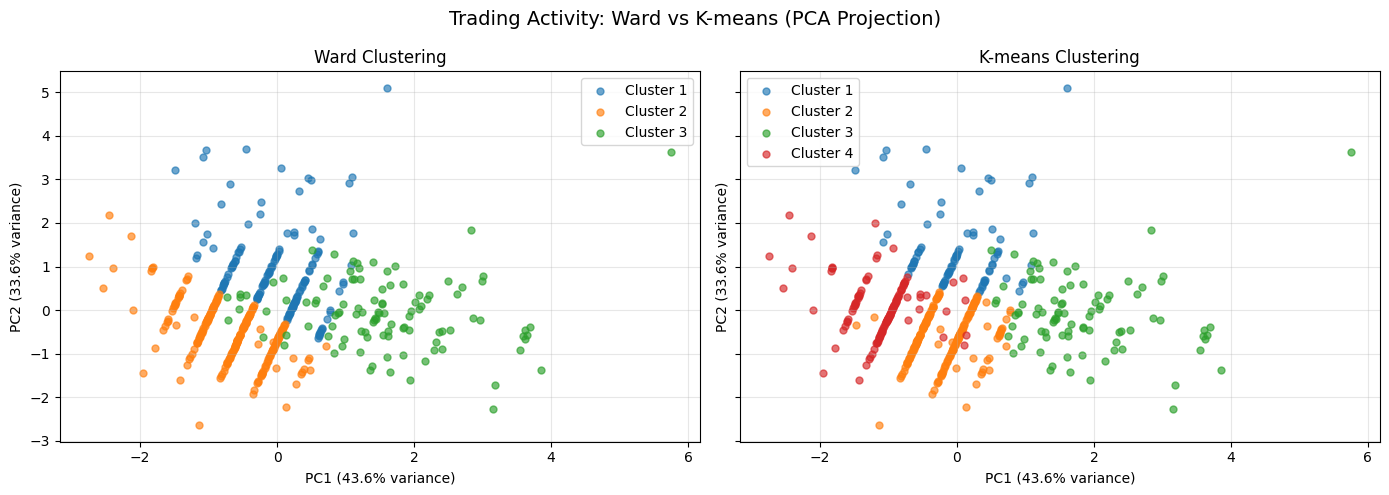

In [ ]:
# Cell 22: RFM visualisation using PCA

from sklearn.decomposition import PCA

pca = PCA(n_components=2)

# PCA applied to the same standardised RFM matrix
pca_values = pca.fit_transform(X_rfm)

pca_df = pd.DataFrame(
    pca_values,
    index=X_rfm.index,
    columns=["PC1", "PC2"]
)

explained = pca.explained_variance_ratio_

print("PCA Explained Variance:")
print(f"PC1: {explained[0]*100:.2f}%")
print(f"PC2: {explained[1]*100:.2f}%")
print(f"Total: {explained.sum()*100:.2f}%")

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    sharex=True,
    sharey=True
)

models = [
    ("Ward Clustering", ward_rfm_labels),
    ("K-means Clustering", km_rfm_labels)
]

for ax, (title, labels) in zip(axes, models):

    for cluster in sorted(labels.unique()):

        tickers = labels.index[labels == cluster]
        subset = pca_df.loc[tickers]

        ax.scatter(
            subset["PC1"],
            subset["PC2"],
            label=f"Cluster {cluster}",
            s=25,
            alpha=0.65
        )

    ax.set_title(title)

    ax.set_xlabel(
        f"PC1 ({explained[0]*100:.1f}% variance)"
    )

    ax.set_ylabel(
        f"PC2 ({explained[1]*100:.1f}% variance)"
    )

    ax.legend()
    ax.grid(alpha=0.3)

fig.suptitle(
    "Trading Activity: Ward vs K-means (PCA Projection)",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    out / "rfm_ward_vs_kmeans_pca.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Cell 23 - Compare clustering agreement

In [ ]:
# Cell 23: Compare algorithms using ARI

from sklearn.metrics import adjusted_rand_score

risk_ari = adjusted_rand_score(
    ward_risk_labels,
    km_risk_labels
)

rfm_ari = adjusted_rand_score(
    ward_rfm_labels,
    km_rfm_labels
)

comparison_summary = pd.DataFrame({
    "Feature Matrix": [
        "Risk and Return",
        "Trading Activity"
    ],
    "Ward k": [2, 3],
    "K-means k": [2, 4],
    "Ward Silhouette": [
        silhouette_score(X_risk, ward_risk_labels),
        silhouette_score(X_rfm, ward_rfm_labels)
    ],
    "K-means Silhouette": [
        silhouette_score(X_risk, km_risk_labels),
        silhouette_score(X_rfm, km_rfm_labels)
    ],
    "Adjusted Rand Index": [
        risk_ari,
        rfm_ari
    ]
})

print("Algorithm Comparison Summary")
display(comparison_summary.round(4))

print("\nRisk and Return - Membership Comparison")
risk_cross = pd.crosstab(
    ward_risk_labels,
    km_risk_labels,
    rownames=["Ward"],
    colnames=["K-means"]
)
display(risk_cross)

print("\nTrading Activity - Membership Comparison")
rfm_cross = pd.crosstab(
    ward_rfm_labels,
    km_rfm_labels,
    rownames=["Ward"],
    colnames=["K-means"]
)
display(rfm_cross)

comparison_summary.to_csv(
    out / "algorithm_comparison_summary.csv",
    index=False
)

risk_cross.to_csv(
    out / "risk_membership_comparison.csv"
)

rfm_cross.to_csv(
    out / "rfm_membership_comparison.csv"
)

print("\nAlgorithm comparison completed successfully.")

Algorithm Comparison Summary


,Feature Matrix,Ward k,K-means k,Ward Silhouette,K-means Silhouette,Adjusted Rand Index
0,Risk and Return,2,2,0.3395,0.3870,0.5976
1,Trading Activity,3,4,0.3352,0.3617,0.4186



Risk and Return - Membership Comparison


K-means,1,2
Ward,,
1,51,343
2,92,0



Trading Activity - Membership Comparison


K-means,1,2,3,4
Ward,,,,
1,81,46,0,14
2,0,146,0,93
3,1,2,90,13



Algorithm comparison completed successfully.


# Cell 24 - RFM correlation analysis

RFM Pearson Correlation Matrix:


,R,F,log1p(M)
R,1.0000,-0.3463,0.1524
F,-0.3463,1.0000,0.0128
log1p(M),0.1524,0.0128,1.0000


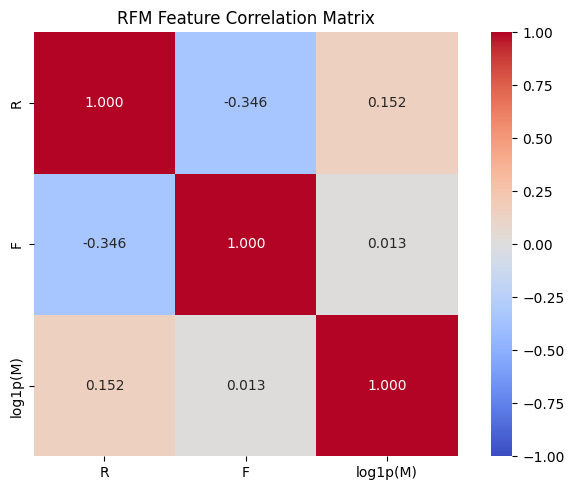


Correlation of actual RFM clustering inputs:


,log1p(R),F,log1p(M)
log1p(R),1.0000,-0.2853,0.1268
F,-0.2853,1.0000,0.0128
log1p(M),0.1268,0.0128,1.0000


In [ ]:
# Cell 24: Correlation analysis

import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Prepare features required by the rubric
corr_data = pd.DataFrame({
    "R": numeric["R"],
    "F": numeric["F"],
    "log1p(M)": np.log1p(numeric["M"])
})

# Pearson correlation matrix
corr_matrix = corr_data.corr(method="pearson")

print("RFM Pearson Correlation Matrix:")
display(corr_matrix.round(4))

# Visualise the correlations
plt.figure(figsize=(7, 5))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title("RFM Feature Correlation Matrix")
plt.tight_layout()

plt.savefig(
    out / "rfm_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Additional check: actual transformed clustering inputs
model_corr = pd.DataFrame({
    "log1p(R)": np.log1p(numeric["R"]),
    "F": numeric["F"],
    "log1p(M)": np.log1p(numeric["M"])
}).corr()

print("\nCorrelation of actual RFM clustering inputs:")
display(model_corr.round(4))

corr_matrix.to_csv(
    out / "rfm_correlations.csv"
)

model_corr.to_csv(
    out / "rfm_model_input_correlations.csv"
)

# Cell 25 -Repeat ward clustering without Monetary

In [ ]:
# Cell 25: Ward clustering without Monetary

from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, cut_tree
from sklearn.metrics import adjusted_rand_score, silhouette_score

# Keep the same transformation used in original RFM clustering
reduced_rfm = pd.DataFrame({
    "R": np.log1p(numeric["R"]),
    "F": numeric["F"]
}, index=numeric.index)

# Standardise the reduced matrix AFRESH
reduced_scaler = StandardScaler()

X_rfm_reduced = pd.DataFrame(
    reduced_scaler.fit_transform(reduced_rfm),
    index=reduced_rfm.index,
    columns=reduced_rfm.columns
)

# Use the original selected Ward cluster count
K_REDUCED = 3

# Apply Ward linkage with Euclidean distance
Z_reduced = linkage(
    X_rfm_reduced.to_numpy(),
    method="ward",
    metric="euclidean"
)

# Obtain exactly 3 clusters
reduced_labels = pd.Series(
    cut_tree(
        Z_reduced,
        n_clusters=K_REDUCED
    ).ravel() + 1,
    index=X_rfm_reduced.index,
    name="ward_reduced_cluster"
)

# Validate the experiment
assert X_rfm_reduced.shape == (486, 2)
assert reduced_labels.index.equals(ward_rfm_labels.index)
assert reduced_labels.nunique() == 3
assert np.isfinite(X_rfm_reduced.to_numpy()).all()

print("Reduced RFM matrix:", X_rfm_reduced.shape)

print("\nReduced Ward cluster sizes:")
print(reduced_labels.value_counts().sort_index())

# Compare the original and reduced cluster memberships
ari_reduced = adjusted_rand_score(
    ward_rfm_labels,
    reduced_labels
)

print("\nAdjusted Rand Index:", round(ari_reduced, 4))

# Silhouette scores
original_silhouette = silhouette_score(
    X_rfm,
    ward_rfm_labels
)

reduced_silhouette = silhouette_score(
    X_rfm_reduced,
    reduced_labels
)

print("Original Ward RFM silhouette:",
      round(original_silhouette, 4))

print("Reduced Ward RFM silhouette:",
      round(reduced_silhouette, 4))

# Membership comparison table
membership_table = pd.crosstab(
    ward_rfm_labels,
    reduced_labels,
    rownames=["Original Ward"],
    colnames=["Without Monetary"]
)

print("\nCluster Membership Comparison:")
display(membership_table)

# Save results
reduced_labels.to_csv(
    out / "ward_rfm_without_monetary.csv",
    index_label="ticker"
)

membership_table.to_csv(
    out / "ward_monetary_removal_membership.csv"
)

print("\nSensitivity experiment completed successfully.")

Reduced RFM matrix: (486, 2)

Reduced Ward cluster sizes:
ward_reduced_cluster
1    252
2    125
3    109
Name: count, dtype: int64

Adjusted Rand Index: 0.349
Original Ward RFM silhouette: 0.3352
Reduced Ward RFM silhouette: 0.5083

Cluster Membership Comparison:


Without Monetary,1,2,3
Original Ward,,,
1,74,59,8
2,173,66,0
3,5,0,101



Sensitivity experiment completed successfully.


# Cell 26 - Compare original and reduced cluster profiles

In [ ]:
# Cell 26: Original vs Reduced Ward profiles

def sensitivity_profile(labels, model_name):

    data = numeric[["R", "F", "M"]].copy()

    data["Cluster"] = labels
    data["M_USD_Bn"] = data["M"] / 1e9

    profile = data.groupby("Cluster").agg(
        Shares=("R", "size"),
        Median_Recency_Days=("R", "median"),
        Median_Frequency=("F", "median"),
        Median_Monetary_USD_Bn=("M_USD_Bn", "median"),
        Mean_Monetary_USD_Bn=("M_USD_Bn", "mean")
    ).reset_index()

    profile.insert(0, "Model", model_name)

    return profile


original_profile = sensitivity_profile(
    ward_rfm_labels,
    "Original RFM"
)

reduced_profile = sensitivity_profile(
    reduced_labels,
    "Without Monetary"
)

profile_comparison = pd.concat(
    [original_profile, reduced_profile],
    ignore_index=True
)

print("Original vs Reduced Ward Cluster Profiles:")
display(profile_comparison.round(4))

# Save comparison
profile_comparison.to_csv(
    out / "ward_monetary_sensitivity_profiles.csv",
    index=False
)

Original vs Reduced Ward Cluster Profiles:


,Model,Cluster,Shares,Median_Recency_Days,Median_Frequency,Median_Monetary_USD_Bn,Mean_Monetary_USD_Bn
0,Original RFM,1,141,11.0,3.0,42.0131,84.4222
1,Original RFM,2,239,11.0,3.0,11.1536,11.6766
2,Original RFM,3,106,46.5,2.0,19.4850,42.0398
3,Without Monetary,1,252,11.0,4.0,14.7358,30.0078
4,Without Monetary,2,125,11.0,2.0,17.6990,34.3379
5,Without Monetary,3,109,46.0,2.0,20.8478,66.9380


# Cell 27 - Visualise Monetary differences

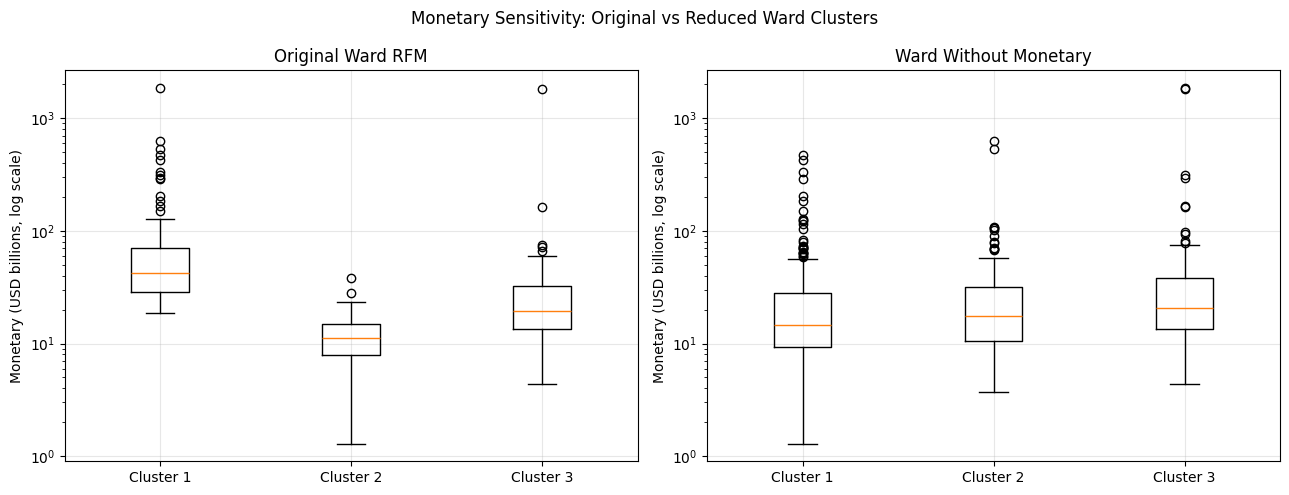

In [ ]:
# Cell 27: Compare Monetary distributions

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5)
)

for ax, labels, title in [
    (
        axes[0],
        ward_rfm_labels,
        "Original Ward RFM"
    ),
    (
        axes[1],
        reduced_labels,
        "Ward Without Monetary"
    )
]:

    clusters = sorted(labels.unique())

    monetary_groups = [
        numeric.loc[labels.index[labels == c], "M"] / 1e9
        for c in clusters
    ]

    ax.boxplot(
        monetary_groups,
        tick_labels=[f"Cluster {c}" for c in clusters]
    )

    ax.set_yscale("log")
    ax.set_title(title)
    ax.set_ylabel("Monetary (USD billions, log scale)")
    ax.grid(alpha=0.3)

plt.suptitle(
    "Monetary Sensitivity: Original vs Reduced Ward Clusters"
)

plt.tight_layout()

plt.savefig(
    out / "ward_monetary_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Cell - 28 Prepare cluster and sector information

In [ ]:
# Cell 28: Prepare data for Task 3.2.1

# Check that sector information is available
assert "sector" in original.columns, (
    "Sector information is missing from the Task 1 feature table."
)

# Clean sector labels without changing the share sample
sectors = (
    original["sector"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
    .fillna("Unknown")
)

# Combine the existing Ward cluster assignments
cluster_view = pd.DataFrame({
    "Risk_Cluster": ward_risk_labels,
    "RFM_Cluster": ward_rfm_labels,
    "Sector": sectors
}, index=X_risk.index)

# Validation
assert cluster_view.shape == (486, 3)
assert cluster_view.notna().all().all()
assert cluster_view["Risk_Cluster"].nunique() == 2
assert cluster_view["RFM_Cluster"].nunique() == 3

print("Total shares:", len(cluster_view))
print("Number of sectors:", cluster_view["Sector"].nunique())

print("\nShares by sector:")
display(cluster_view["Sector"].value_counts())

print("\nFinal Ward Risk and Return profiles:")
display(
    ward_risk_profiles[
        ward_risk_profiles["k"] == 2
    ].round(4)
)

print("\nFinal Ward RFM profiles:")
display(
    ward_rfm_profiles[
        ward_rfm_profiles["k"] == 3
    ].round(4)
)

cluster_view.to_csv(
    out / "task3_cluster_sector_data.csv",
    index_label="ticker"
)

Total shares: 486
Number of sectors: 11

Shares by sector:


,count
Sector,
Industrials,78
Information Technology,74
Financials,74
Health Care,58
Consumer Discretionary,47
Consumer Staples,32
Utilities,30
Real Estate,30
Materials,23



Final Ward Risk and Return profiles:


,Cluster,k,Shares,Mean_Weekly_Return_Pct,Mean_Beta
0,1,2,394,0.2048,0.8979
1,2,2,92,0.6321,1.2981



Final Ward RFM profiles:


,Cluster,k,Shares,Median_Recency,Median_Frequency,Median_Monetary_USD_Bn
2,1,3,141,11.0,3.0,42.0131
3,2,3,239,11.0,3.0,11.1536
4,3,3,106,46.5,2.0,19.4850


# Cell 29 - Risk and Return vs RFM cluster heatmap

Cluster Membership Counts:


RFM_Cluster,1,2,3
Risk_Cluster,,,
1,106,207,81
2,35,32,25



Cluster Membership Percentages:


RFM_Cluster,1,2,3
Risk_Cluster,,,
1,26.90,52.54,20.56
2,38.04,34.78,27.17


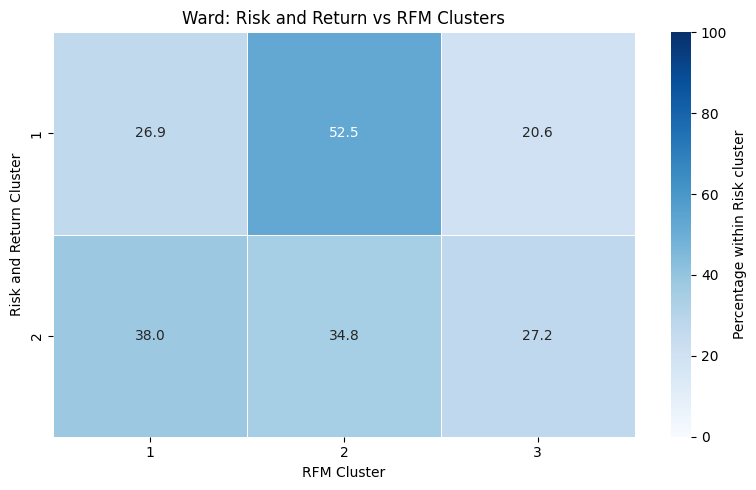

In [ ]:
# Cell 29: Compare cluster memberships

import seaborn as sns

# Count shares in each combination
cross_counts = pd.crosstab(
    cluster_view["Risk_Cluster"],
    cluster_view["RFM_Cluster"]
)

# Convert counts to percentages within Risk clusters
cross_pct = cross_counts.div(
    cross_counts.sum(axis=1),
    axis=0
) * 100

print("Cluster Membership Counts:")
display(cross_counts)

print("\nCluster Membership Percentages:")
display(cross_pct.round(2))

# Heatmap
plt.figure(figsize=(8, 5))

sns.heatmap(
    cross_pct,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar_kws={"label": "Percentage within Risk cluster"}
)

plt.title("Ward: Risk and Return vs RFM Clusters")
plt.xlabel("RFM Cluster")
plt.ylabel("Risk and Return Cluster")

plt.tight_layout()

plt.savefig(
    out / "task3_risk_rfm_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Cell 30 - Sector composition charts

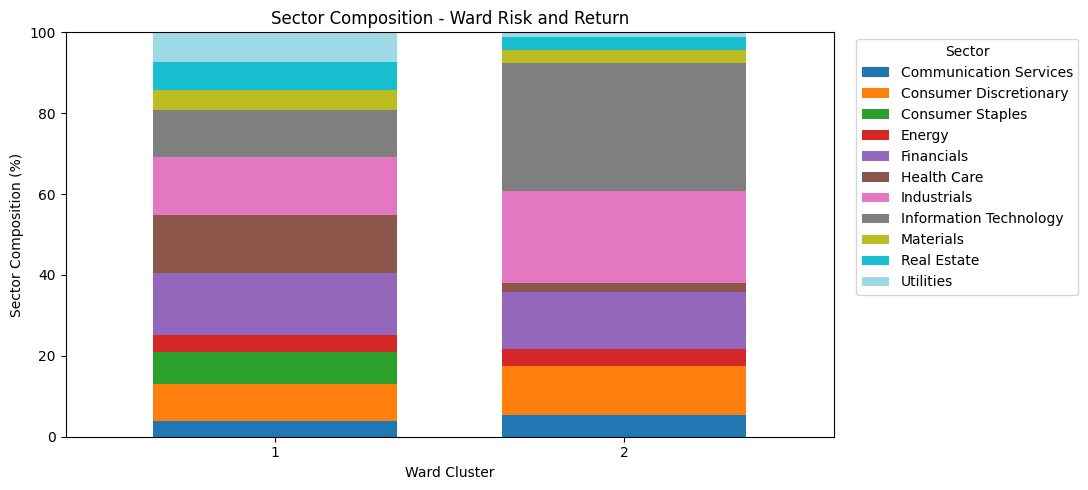

Sector Composition - Ward Risk and Return


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Risk_Cluster,,,,,,,,,,,
1,3.81,9.14,8.12,4.06,15.48,14.21,14.47,11.42,5.08,6.85,7.36
2,5.43,11.96,0.00,4.35,14.13,2.17,22.83,31.52,3.26,3.26,1.09


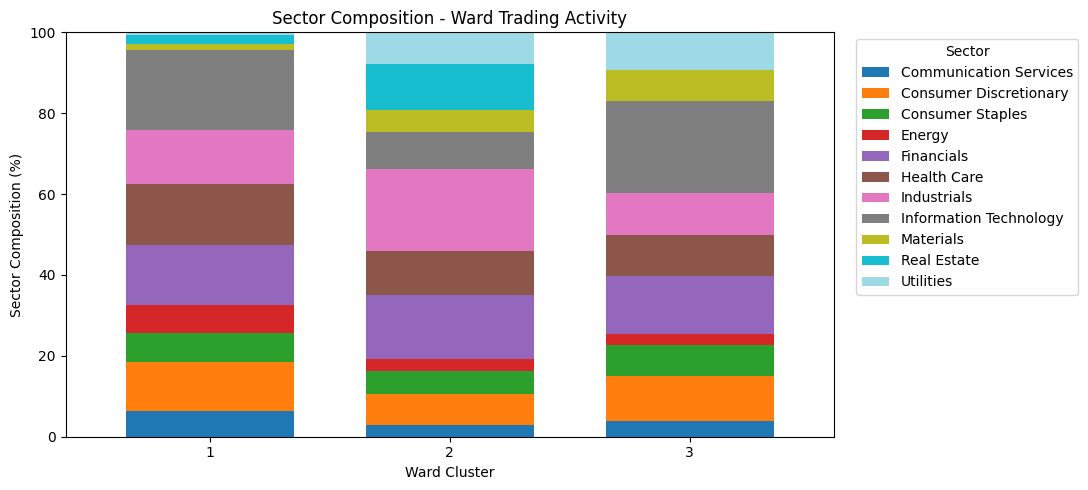

Sector Composition - Ward Trading Activity


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
RFM_Cluster,,,,,,,,,,,
1,6.38,12.06,7.09,7.09,14.89,14.89,13.48,19.86,1.42,2.13,0.71
2,2.93,7.53,5.86,2.93,15.90,10.88,20.08,9.21,5.44,11.30,7.95
3,3.77,11.32,7.55,2.83,14.15,10.38,10.38,22.64,7.55,0.00,9.43



Overall sector distribution (%):


,proportion
Sector,
Industrials,16.05
Information Technology,15.23
Financials,15.23
Health Care,11.93
Consumer Discretionary,9.67
Consumer Staples,6.58
Utilities,6.17
Real Estate,6.17
Materials,4.73


In [ ]:
# Cell 30: Sector composition analysis

def plot_sector_composition(cluster_column, title, filename):

    # Percentage distribution of sectors within each cluster
    sector_counts = pd.crosstab(
        cluster_view[cluster_column],
        cluster_view["Sector"]
    )

    sector_pct = sector_counts.div(
        sector_counts.sum(axis=1),
        axis=0
    ) * 100

    # Plot
    fig, ax = plt.subplots(figsize=(11, 5))

    sector_pct.plot(
        kind="bar",
        stacked=True,
        ax=ax,
        colormap="tab20",
        width=0.7
    )

    ax.set_title(title)
    ax.set_xlabel("Ward Cluster")
    ax.set_ylabel("Sector Composition (%)")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=0)

    ax.legend(
        title="Sector",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.tight_layout()

    plt.savefig(
        out / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print(title)
    display(sector_pct.round(2))

    return sector_pct


# Risk and Return sector composition
sector_risk = plot_sector_composition(
    "Risk_Cluster",
    "Sector Composition - Ward Risk and Return",
    "task3_sector_risk.png"
)

# RFM sector composition
sector_rfm = plot_sector_composition(
    "RFM_Cluster",
    "Sector Composition - Ward Trading Activity",
    "task3_sector_rfm.png"
)

# Overall sector distribution for comparison
print("\nOverall sector distribution (%):")
display(
    (
        cluster_view["Sector"]
        .value_counts(normalize=True) * 100
    ).round(2)
)

# Save sector percentages
sector_risk.to_csv(out / "task3_sector_risk.csv")
sector_rfm.to_csv(out / "task3_sector_rfm.csv")